# Emotion Classification with Attention
### Multi-architecture comparison: LSTM · GRU · BiLSTM+Attention · Fine-tuned DistilBERT

**Objective:** Classify text into 6 core (Ekman) emotions — joy, sadness, anger, fear, surprise, disgust — using the GoEmotions dataset.

**Pipeline:**
1. Load & explore GoEmotions
2. Map 28 raw labels → 6 target emotion classes (Ekman mapping)
3. Clean & tokenize text, pad sequences
4. Build embedding layer with pre-trained GloVe/FastText vectors
5. Train & compare: LSTM, GRU, BiLSTM+Attention, DistilBERT
6. Evaluate: Accuracy, Macro F1, per-class precision/recall, confusion matrix
7. Visualize attention weights
8. Deploy as Gradio app

**Completed version:** unified evaluation, per-class reports, confusion matrices, attention heatmaps, model selection, Gradio GUI, standalone app, and artifact export. Run All executes every stage.


**Memory-fix build (Kaggle):** TensorFlow GPU memory is capped at 3 GiB before any TensorFlow model operations so that PyTorch can subsequently load DistilBERT. DistilBERT microbatch size is 4 with gradient accumulation; diagnostic RAM/VRAM snapshots are printed. The cap may need adjustment for a different GPU and cannot be applied without a fresh kernel. This notebook has been syntax-checked, **not** executed end-to-end on Kaggle.

In [6]:
# ============================================================
# 1. Setup
# ============================================================
!pip install -q datasets gensim tensorflow transformers gradio seaborn


In [7]:
import numpy as np
import pandas as pd
import re
import json
import random
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

# IMPORTANT: configure TensorFlow GPU BEFORE any TF GPU operation.
# TensorFlow and PyTorch share the same Kaggle GPU in this notebook.
# Cap TensorFlow allocation so DistilBERT/PyTorch has VRAM available later.
_TF_GPUS = tf.config.list_physical_devices('GPU')
if _TF_GPUS:
    try:
        tf.config.set_logical_device_configuration(
            _TF_GPUS[0],
            [tf.config.LogicalDeviceConfiguration(memory_limit=3072)]
        )
        print('TensorFlow VRAM capped at 3072 MiB; remaining GPU memory available to PyTorch.')
    except RuntimeError as exc:
        print('WARNING: GPU already initialized before TF cap:', exc)
        print('RESTART KERNEL and Run All to apply cap; memory fix cannot work otherwise.')
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from datasets import load_dataset
import datasets.config as ds_config
ds_config.TORCHVISION_AVAILABLE = False  # avoid datasets' broken torchvision.io.VideoReader import path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                              confusion_matrix, classification_report)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow VRAM capped at 3072 MiB; remaining GPU memory available to PyTorch.
TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load GoEmotions Dataset

We use the `simplified` config of GoEmotions from HuggingFace `datasets` (matches the official Google GoEmotions release). It contains 28 raw emotion labels (27 emotions + neutral).

In [8]:
# NOTE: use the full "namespace/name" repo id — the short alias "go_emotions"
# relies on a legacy loading script and breaks on newer datasets/huggingface_hub
# versions (HfUriError). google-research-datasets/go_emotions is the current
# parquet-based repo and works reliably.
raw = load_dataset("google-research-datasets/go_emotions", "simplified")
print(raw)

label_names = raw["train"].features["labels"].feature.names
print(f"\nNumber of raw emotion labels: {len(label_names)}")
print(label_names)


DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})

Number of raw emotion labels: 28
['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [9]:
# Peek at a few examples
for i in range(5):
    ex = raw["train"][i]
    labels = [label_names[l] for l in ex["labels"]]
    print(f"Text: {ex['text']}")
    print(f"Raw labels: {labels}\n")


Text: My favourite food is anything I didn't have to cook myself.
Raw labels: ['neutral']

Text: Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead
Raw labels: ['neutral']

Text: WHY THE FUCK IS BAYLESS ISOING
Raw labels: ['anger']

Text: To make her feel threatened
Raw labels: ['fear']

Text: Dirty Southern Wankers
Raw labels: ['annoyance']



## 3. Map Raw Labels → 6 Target Emotion Classes

We use the **official Ekman mapping** published by Google in the GoEmotions repo, which groups the 27 fine-grained emotions (+neutral) into Ekman's 6 basic emotions + neutral. We then **drop `neutral`** and any multi-label / ambiguous examples, keeping only single-label examples that map cleanly to one of our 6 target classes.

In [10]:
# Official Ekman grouping (from Google's GoEmotions repo: ekman_mapping.json)
EKMAN_MAPPING = {
    "anger":    ["anger", "annoyance", "disapproval"],
    "disgust":  ["disgust"],
    "fear":     ["fear", "nervousness"],
    "joy":      ["joy", "amusement", "approval", "excitement", "gratitude",
                 "love", "optimism", "relief", "pride", "admiration",
                 "desire", "caring"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
}
TARGET_CLASSES = list(EKMAN_MAPPING.keys())  # ['anger','disgust','fear','joy','sadness','surprise']
print("Target classes:", TARGET_CLASSES)

# Build reverse lookup: raw_label_name -> target_class (or None for neutral/unmapped)
raw_to_target = {}
for target, raw_group in EKMAN_MAPPING.items():
    for raw_label in raw_group:
        raw_to_target[raw_label] = target

print(f"\n{len(raw_to_target)} / {len(label_names)} raw labels mapped (remaining: neutral)")


Target classes: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']

27 / 28 raw labels mapped (remaining: neutral)


In [11]:
def map_example_to_target(example):
    """Map a GoEmotions example to a single target class.
    Rules:
      - Get the set of target classes implied by its raw labels.
      - Keep the example ONLY if it maps to exactly ONE target class
        (drops neutral-only and cross-class ambiguous examples).
    """
    raw_labels = [label_names[l] for l in example["labels"]]
    targets = {raw_to_target[r] for r in raw_labels if r in raw_to_target}
    if len(targets) == 1:
        return {"emotion": list(targets)[0], "keep": True}
    return {"emotion": None, "keep": False}

def build_clean_split(split):
    texts, emotions = [], []
    for ex in raw[split]:
        mapped = map_example_to_target(ex)
        if mapped["keep"]:
            texts.append(ex["text"])
            emotions.append(mapped["emotion"])
    df = pd.DataFrame({"text": texts, "emotion": emotions})
    return df

train_df = build_clean_split("train")
val_df   = build_clean_split("validation")
test_df  = build_clean_split("test")

print("Train:", train_df.shape, " Val:", val_df.shape, " Test:", test_df.shape)
train_df.head()


Train: (28104, 2)  Val: (3527, 2)  Test: (3539, 2)


,text,emotion
0,WHY THE FUCK IS BAYLESS ISOING,anger
1,To make her feel threatened,fear
2,Dirty Southern Wankers,anger
3,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,surprise
4,Yes I heard abt the f bombs! That has to be wh...,joy


/tmp/ipykernel_1814/3658231219.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="emotion", order=order, ax=ax, palette="viridis")
/tmp/ipykernel_1814/3658231219.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="emotion", order=order, ax=ax, palette="viridis")
/tmp/ipykernel_1814/3658231219.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="emotion", order=order, ax=ax, palette="viridis")


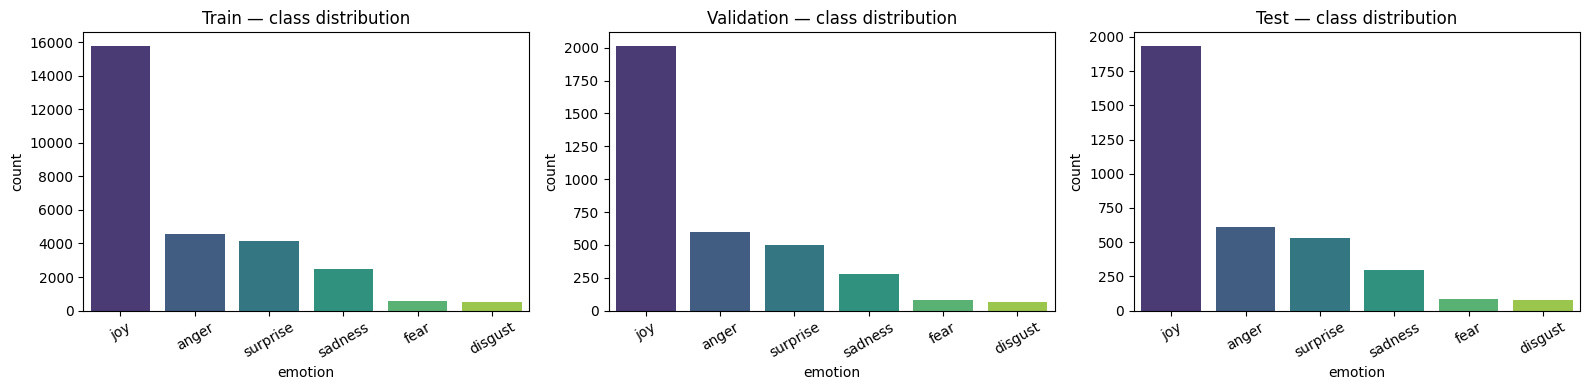

emotion
joy         15809
anger        4590
surprise     4160
sadness      2455
fear          566
disgust       524
Name: count, dtype: int64


In [12]:
# Class distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, [("Train", train_df), ("Validation", val_df), ("Test", test_df)]):
    order = df["emotion"].value_counts().index
    sns.countplot(data=df, x="emotion", order=order, ax=ax, palette="viridis")
    ax.set_title(f"{name} — class distribution")
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

print(train_df["emotion"].value_counts())


## 4. Text Cleaning & Tokenization

Steps:
- Lowercase, strip URLs/mentions/extra whitespace, keep basic punctuation that carries emotional signal (`!`, `?`)
- Encode target labels (`emotion` string → integer id)
- Fit a Keras `Tokenizer` on the **training set only**
- Convert texts → integer sequences → pad to a fixed length


In [13]:
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)          # URLs
    text = re.sub(r"@\w+", " ", text)                      # mentions
    text = re.sub(r"\[NAME\]|\[RELIGION\]|\[.*?\]", " ", text)  # GoEmotions redaction tags
    text = re.sub(r"[^a-zA-Z!?']", " ", text)               # keep letters + ! ? '
    text = re.sub(r"\s+", " ", text).strip()
    return text

for df in (train_df, val_df, test_df):
    df["clean_text"] = df["text"].apply(clean_text)

train_df = train_df[train_df["clean_text"].str.len() > 0].reset_index(drop=True)
val_df   = val_df[val_df["clean_text"].str.len() > 0].reset_index(drop=True)
test_df  = test_df[test_df["clean_text"].str.len() > 0].reset_index(drop=True)

train_df[["text", "clean_text", "emotion"]].head()


,text,clean_text,emotion
0,WHY THE FUCK IS BAYLESS ISOING,why the fuck is bayless isoing,anger
1,To make her feel threatened,to make her feel threatened,fear
2,Dirty Southern Wankers,dirty southern wankers,anger
3,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,omg peyton isn't good enough to help us in the...,surprise
4,Yes I heard abt the f bombs! That has to be wh...,yes i heard abt the f bombs! that has to be wh...,joy


In [14]:
# Label encoding
label2id = {label: i for i, label in enumerate(TARGET_CLASSES)}
id2label = {i: label for label, i in label2id.items()}
print(label2id)

for df in (train_df, val_df, test_df):
    df["label_id"] = df["emotion"].map(label2id)


{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'sadness': 4, 'surprise': 5}


count    28102.000000
mean        12.737065
std          6.648651
min          1.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         31.000000
Name: clean_text, dtype: float64


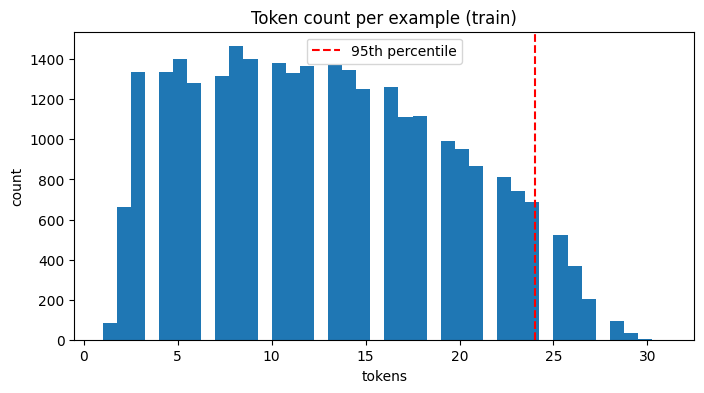

Chosen MAX_LEN: 24


In [15]:
# Sequence length analysis to pick MAX_LEN
lengths = train_df["clean_text"].str.split().apply(len)
print(lengths.describe())

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=40)
plt.axvline(lengths.quantile(0.95), color="red", linestyle="--", label="95th percentile")
plt.title("Token count per example (train)")
plt.xlabel("tokens"); plt.ylabel("count"); plt.legend()
plt.show()

MAX_LEN = int(lengths.quantile(0.95))
print("Chosen MAX_LEN:", MAX_LEN)


In [16]:
VOCAB_SIZE = 20000
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(train_df["clean_text"])

def texts_to_padded(df):
    seqs = tokenizer.texts_to_sequences(df["clean_text"])
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train = texts_to_padded(train_df)
X_val   = texts_to_padded(val_df)
X_test  = texts_to_padded(test_df)

y_train = train_df["label_id"].values
y_val   = val_df["label_id"].values
y_test  = test_df["label_id"].values

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)
print("Actual vocab size:", min(VOCAB_SIZE, len(tokenizer.word_index) + 1))


X_train: (28102, 24)  X_val: (3527, 24)  X_test: (3539, 24)
Actual vocab size: 20000


In [17]:
# Sanity check: decode one padded sequence back to words
idx2word = {v: k for k, v in tokenizer.word_index.items()}
sample = X_train[0]
decoded = " ".join(idx2word.get(i, "") for i in sample if i != 0)
print("Original :", train_df.loc[0, "clean_text"])
print("Decoded  :", decoded)
print("Label    :", id2label[y_train[0]])


Original : why the fuck is bayless isoing
Decoded  : why the fuck is bayless isoing
Label    : anger


## 5. Pre-trained Word Embeddings (GloVe)

We build an embedding matrix from **GloVe 6B 100d** vectors, initialize the Keras `Embedding` layer with it, and keep it **trainable=True** so the model can fine-tune embeddings for the emotion-classification task while still starting from meaningful pre-trained representations.

> We use `gensim.downloader` to fetch GloVe — no manual file download needed.


In [18]:
import gensim.downloader as api

EMBEDDING_DIM = 100
print("Downloading GloVe 6B 100d (first run only, cached after)...")
glove_vectors = api.load("glove-wiki-gigaword-100")
print("Loaded. Vocab size in GloVe:", len(glove_vectors))


Loaded. Vocab size in GloVe: 400000


In [19]:
actual_vocab_size = min(VOCAB_SIZE, len(tokenizer.word_index) + 1)

embedding_matrix = np.zeros((actual_vocab_size, EMBEDDING_DIM))

hits, misses = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= actual_vocab_size:
        continue
    if word in glove_vectors:
        embedding_matrix[idx] = glove_vectors[word]
        hits += 1
    else:
        misses += 1
        # leave as zeros (or could init randomly)

print(f"Words found in GloVe: {hits}")
print(f"Words missing (OOV):  {misses}")
print(f"Coverage: {hits / (hits + misses):.2%}")
print("Embedding matrix shape:", embedding_matrix.shape)


Words found in GloVe: 17461
Words missing (OOV):  2538
Coverage: 87.31%
Embedding matrix shape: (20000, 100)


In [20]:
# Free the raw GloVe model from memory now that we've built the matrix
del glove_vectors
import gc; gc.collect()

# Quick sanity check: nearest-ish words via embedding matrix (cosine similarity)
from numpy.linalg import norm

def most_similar_in_matrix(word, top_n=5):
    if word not in tokenizer.word_index:
        print(f"'{word}' not in vocab")
        return
    idx = tokenizer.word_index[word]
    vec = embedding_matrix[idx]
    if norm(vec) == 0:
        print(f"'{word}' has a zero vector (was OOV in GloVe)")
        return
    sims = embedding_matrix @ vec / (norm(embedding_matrix, axis=1) * norm(vec) + 1e-8)
    top_idx = np.argsort(-sims)[1:top_n+1]
    idx2word_local = {v: k for k, v in tokenizer.word_index.items()}
    for i in top_idx:
        print(f"  {idx2word_local.get(i, '<UNK>')}  (sim={sims[i]:.3f})")

print("Words most similar to 'happy':")
most_similar_in_matrix("happy")


Words most similar to 'happy':
  feel  (sim=0.813)
  i  (sim=0.794)
  really  (sim=0.790)
  glad  (sim=0.783)
  good  (sim=0.782)


## 6. Model 1 — LSTM

A simple baseline: `Embedding (GloVe) → LSTM → Dense → Softmax(6)`.

We'll reuse this same training/evaluation pattern for GRU and BiLSTM+Attention later, so results are directly comparable.


In [21]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Embedding, LSTM, GRU, Bidirectional,
                                      Dense, Dropout, Layer)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

NUM_CLASSES = len(TARGET_CLASSES)

y_train_cat = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_cat   = to_categorical(y_val, num_classes=NUM_CLASSES)
y_test_cat  = to_categorical(y_test, num_classes=NUM_CLASSES)

# Class weights to handle imbalance from the Ekman grouping (e.g. 'joy' is large)
from sklearn.utils.class_weight import compute_class_weight
class_weights_arr = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weights_arr)}
print("Class weights:", {id2label[k]: round(v, 2) for k, v in class_weight_dict.items()})


Class weights: {'anger': np.float64(1.02), 'disgust': np.float64(8.96), 'fear': np.float64(8.28), 'joy': np.float64(0.3), 'sadness': np.float64(1.91), 'surprise': np.float64(1.13)}


In [22]:
def build_lstm_model():
    inputs = Input(shape=(MAX_LEN,), name="input_ids")
    x = Embedding(input_dim=actual_vocab_size, output_dim=EMBEDDING_DIM,
                  weights=[embedding_matrix], trainable=True, mask_zero=True,
                  name="embedding")(inputs)
    x = LSTM(128, dropout=0.3, recurrent_dropout=0.2)(x)
    x = Dense(64, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(NUM_CLASSES, activation="softmax")(x)
    model = Model(inputs, outputs, name="LSTM_model")
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

lstm_model = build_lstm_model()
lstm_model.summary()


Model: "LSTM_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 24)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 24, 100)   │  2,000,000 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 24)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    117,248 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │        390 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,125,894 (8.11 MB)

 Trainable params: 2,125,894 (8.11 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

lstm_history = lstm_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 44s 86ms/step - accuracy: 0.3550 - loss: 1.6761 - val_accuracy: 0.5152 - val_loss: 1.3828
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 38s 85ms/step - accuracy: 0.5783 - loss: 1.2178 - val_accuracy: 0.6388 - val_loss: 0.9791
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 37s 85ms/step - accuracy: 0.6616 - loss: 0.9418 - val_accuracy: 0.6870 - val_loss: 0.8962
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 38s 85ms/step - accuracy: 0.7101 - loss: 0.7972 - val_accuracy: 0.6796 - val_loss: 0.8855
Epoch 5/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 38s 87ms/step - accuracy: 0.7370 - loss: 0.7007 - val_accuracy: 0.6850 - val_loss: 0.8814
Epoch 6/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 39s 89ms/step - accuracy: 0.7653 - loss: 0.5968 - val_accuracy: 0.6836 - val_loss: 0.8957
Epoch 7/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 39s 88ms/step - accuracy: 0.7912 - loss: 0.5136 - val_accuracy: 0.6978 - val_loss: 0.8887
Epoch 8/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 38s 86ms/step - accuracy: 0.8119 - loss: 0.4452 - 

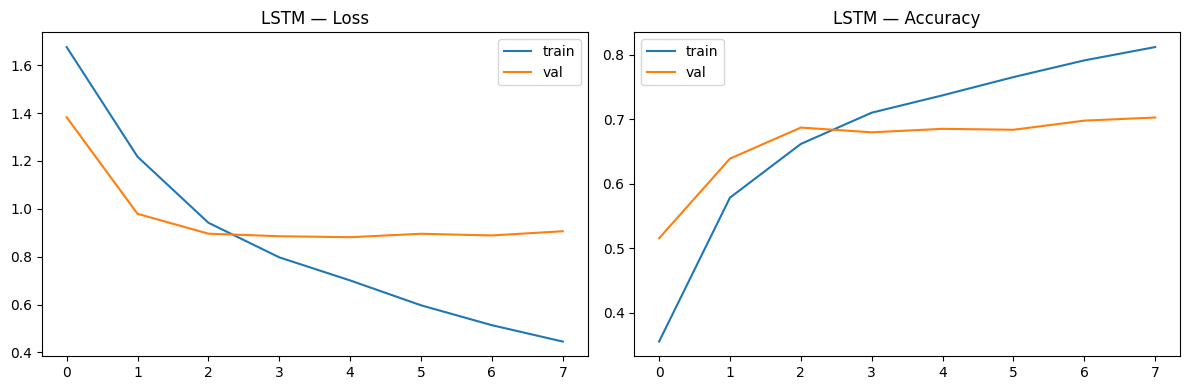

In [24]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title(f"{title} — Loss"); axes[0].legend()
    axes[1].plot(history.history["accuracy"], label="train")
    axes[1].plot(history.history["val_accuracy"], label="val")
    axes[1].set_title(f"{title} — Accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_history(lstm_history, "LSTM")


In [25]:
lstm_model.save("lstm_model.keras")
print("Saved lstm_model.keras")


Saved lstm_model.keras


## 7. Model 2 — GRU

Same pipeline as the LSTM model, swapping the recurrent layer for a `GRU`. GRU has fewer gates than LSTM (no separate cell state), so it's typically faster to train with comparable performance — useful to confirm empirically here.


In [26]:
def build_gru_model():
    inputs = Input(shape=(MAX_LEN,), name="input_ids")
    x = Embedding(input_dim=actual_vocab_size, output_dim=EMBEDDING_DIM,
                  weights=[embedding_matrix], trainable=True, mask_zero=True,
                  name="embedding")(inputs)
    x = GRU(128, dropout=0.3, recurrent_dropout=0.2)(x)
    x = Dense(64, activation="relu")(x)
    x = Dropout(0.4)(x)
    outputs = Dense(NUM_CLASSES, activation="softmax")(x)
    model = Model(inputs, outputs, name="GRU_model")
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

gru_model = build_gru_model()
gru_model.summary()


Model: "GRU_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 24)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 24, 100)   │  2,000,000 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 24)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     88,320 │ embedding[0][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 6)         │        390 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,096,966 (8.00 MB)

 Trainable params: 2,096,966 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
early_stop_gru = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

gru_history = gru_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop_gru],
    verbose=1
)


Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.3511 - loss: 1.6693 - val_accuracy: 0.6033 - val_loss: 1.1747
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 72ms/step - accuracy: 0.5780 - loss: 1.1829 - val_accuracy: 0.6323 - val_loss: 0.9972
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 73ms/step - accuracy: 0.6561 - loss: 0.9626 - val_accuracy: 0.6598 - val_loss: 0.9357
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 73ms/step - accuracy: 0.7034 - loss: 0.8163 - val_accuracy: 0.6751 - val_loss: 0.9084
Epoch 5/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 72ms/step - accuracy: 0.7287 - loss: 0.7251 - val_accuracy: 0.6842 - val_loss: 0.8963
Epoch 6/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 72ms/step - accuracy: 0.7544 - loss: 0.6341 - val_accuracy: 0.6978 - val_loss: 0.8723
Epoch 7/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 73ms/step - accuracy: 0.7770 - loss: 0.5613 - val_accuracy: 0.6963 - val_loss: 0.8725
Epoch 8/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 32s 73ms/step - accuracy: 0.7960 - loss: 0.4968 - 

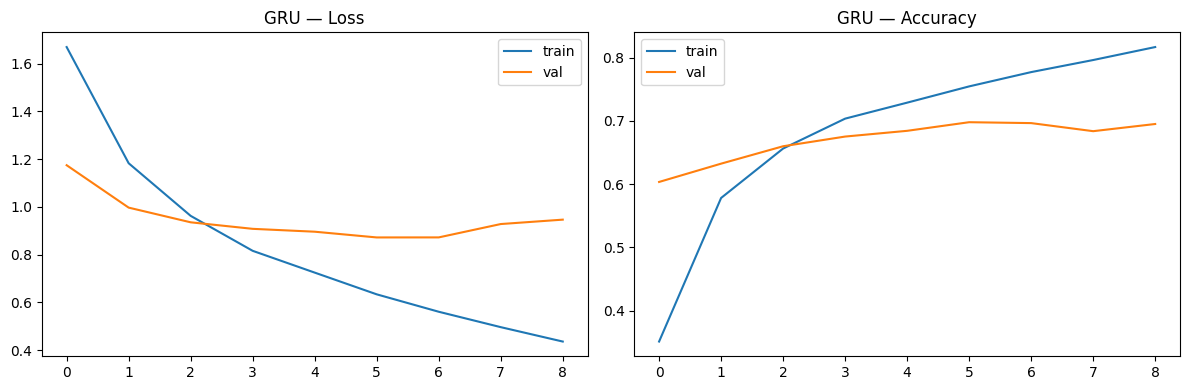

In [28]:
plot_history(gru_history, "GRU")


In [29]:
gru_model.save("gru_model.keras")
print("Saved gru_model.keras")


Saved gru_model.keras


## 8. Model 3 — BiLSTM + Attention

Keras doesn't ship a ready-made "attention over sequence" layer for this use case, so we implement a small **additive (Bahdanau-style) attention layer** from scratch:

$$e_t = v^T \tanh(W h_t + b), \qquad \alpha = \text{softmax}(e), \qquad \text{context} = \sum_t \alpha_t h_t$$

where $h_t$ are the BiLSTM hidden states at each timestep. The layer returns **both** the pooled context vector (fed to the classifier) **and** the attention weights $\alpha$ (used later for the heatmap visualization) — that's why we subclass `Layer` instead of using a plain `Dense`/`Lambda` chain.


In [30]:
@tf.keras.utils.register_keras_serializable(package="EmotionProject")
class AdditiveAttention(Layer):
    """Bahdanau-style additive attention over BiLSTM hidden states.
    Input:  (batch, timesteps, hidden_dim)
    Output: context (batch, hidden_dim), attention_weights (batch, timesteps)
    """
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.W = self.add_weight(name="att_W", shape=(input_shape[-1], self.units),
                                  initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="att_b", shape=(self.units,),
                                  initializer="zeros", trainable=True)
        self.v = self.add_weight(name="att_v", shape=(self.units, 1),
                                  initializer="glorot_uniform", trainable=True)
        super().build(input_shape)

    def call(self, hidden_states, mask=None):
        # hidden_states: (batch, T, hidden_dim)
        score = tf.tanh(tf.tensordot(hidden_states, self.W, axes=1) + self.b)  # (batch, T, units)
        score = tf.tensordot(score, self.v, axes=1)                            # (batch, T, 1)
        score = tf.squeeze(score, axis=-1)                                     # (batch, T)

        if mask is not None:
            score += (1.0 - tf.cast(mask, tf.float32)) * -1e9  # mask padding tokens

        weights = tf.nn.softmax(score, axis=1)                                 # (batch, T)
        weights_expanded = tf.expand_dims(weights, axis=-1)                    # (batch, T, 1)
        context = tf.reduce_sum(hidden_states * weights_expanded, axis=1)      # (batch, hidden_dim)
        return context, weights

    def compute_mask(self, inputs, mask=None):
        return None  # don't propagate mask further

    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units})
        return config


In [31]:
def build_bilstm_attention_model():
    inputs = Input(shape=(MAX_LEN,), name="input_ids")
    x = Embedding(input_dim=actual_vocab_size, output_dim=EMBEDDING_DIM,
                  weights=[embedding_matrix], trainable=True, mask_zero=True,
                  name="embedding")(inputs)
    hidden_states = Bidirectional(
        LSTM(64, return_sequences=True, dropout=0.3, recurrent_dropout=0.2),
        name="bilstm"
    )(x)  # (batch, MAX_LEN, 128)

    context, attn_weights = AdditiveAttention(units=64, name="attention")(hidden_states)

    x = Dense(64, activation="relu")(context)
    x = Dropout(0.4)(x)
    outputs = Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)

    # Main model for training (single output)
    train_model = Model(inputs, outputs, name="BiLSTM_Attention_model")
    train_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

    # Companion model sharing the same weights, also exposing attention weights
    # (used later for the attention heatmap visualization)
    attn_model = Model(inputs, [outputs, attn_weights], name="BiLSTM_Attention_with_weights")

    return train_model, attn_model

bilstm_attn_model, bilstm_attn_weights_model = build_bilstm_attention_model()
bilstm_attn_model.summary()


Model: "BiLSTM_Attention_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 24)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 24, 100)   │  2,000,000 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 24)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 24, 128)   │     84,480 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 128),     │      8,320 │ bilstm[0][0],     │
│ (AdditiveAttention) │ (None, 24)]       │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier (Dense)  │ (None, 6)         │        390 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,101,446 (8.02 MB)

 Trainable params: 2,101,446 (8.02 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
early_stop_bilstm = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

bilstm_history = bilstm_attn_model.fit(
    X_train, y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop_bilstm],
    verbose=1
)


Epoch 1/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 64s 132ms/step - accuracy: 0.4385 - loss: 1.4450 - val_accuracy: 0.6059 - val_loss: 1.0899
Epoch 2/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 57s 130ms/step - accuracy: 0.6354 - loss: 1.0111 - val_accuracy: 0.6609 - val_loss: 0.9571
Epoch 3/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 57s 129ms/step - accuracy: 0.6877 - loss: 0.8730 - val_accuracy: 0.6827 - val_loss: 0.9124
Epoch 4/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 57s 129ms/step - accuracy: 0.7288 - loss: 0.7638 - val_accuracy: 0.6819 - val_loss: 0.9219
Epoch 5/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - accuracy: 0.7547 - loss: 0.6697 - val_accuracy: 0.6924 - val_loss: 0.9206
Epoch 6/15
440/440 ━━━━━━━━━━━━━━━━━━━━ 58s 131ms/step - accuracy: 0.7793 - loss: 0.5797 - val_accuracy: 0.6878 - val_loss: 0.9392


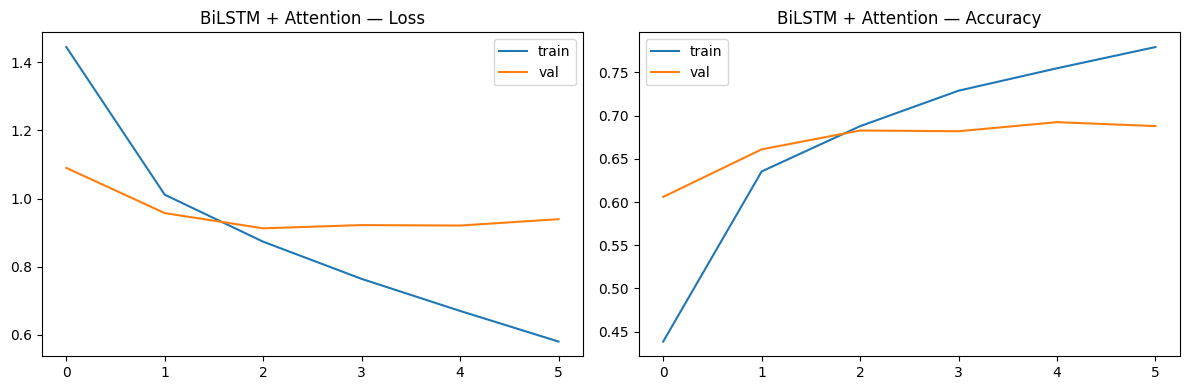

In [33]:
plot_history(bilstm_history, "BiLSTM + Attention")


In [34]:
# Quick sanity check on the attention mechanism: inspect weights for one example
sample_idx = 0
sample_input = X_val[sample_idx:sample_idx+1]
probs, weights = bilstm_attn_weights_model.predict(sample_input, verbose=0)

tokens = [idx2word.get(i, "") for i in sample_input[0] if i != 0]
w = weights[0][:len(tokens)]

print("Text:", val_df.loc[sample_idx, "clean_text"])
print("True label:", val_df.loc[sample_idx, "emotion"])
print("Predicted :", id2label[np.argmax(probs[0])])
print()
for tok, wt in zip(tokens, w):
    print(f"  {tok:15s} attn={wt:.3f}")


Text: you know the answer man you are programmed to capture those codes they send you don t avoid them!
True label: joy
Predicted : surprise

  you             attn=0.033
  know            attn=0.454
  the             attn=0.009
  answer          attn=0.069
  man             attn=0.020
  you             attn=0.010
  are             attn=0.008
  <OOV>           attn=0.068
  to              attn=0.006
  capture         attn=0.022
  those           attn=0.007
  codes           attn=0.007
  they            attn=0.005
  send            attn=0.052
  you             attn=0.008
  don             attn=0.110
  t               attn=0.016
  avoid           attn=0.084
  them            attn=0.011


In [35]:
bilstm_attn_model.save("bilstm_attention_model.keras")
bilstm_attn_weights_model.save("bilstm_attention_weights_model.keras")
print("Saved BiLSTM+Attention models.")


Saved BiLSTM+Attention models.


## 9. Model 4 — Fine-tune DistilBERT (HuggingFace Trainer)

Unlike the RNN-based models above, DistilBERT ships with its own subword tokenizer and pre-trained contextual representations, so here we feed it the **raw `text`** column (not `clean_text` / the Keras `Tokenizer`) and fine-tune the whole encoder plus a classification head end-to-end using the HuggingFace `Trainer` API.

Steps:
1. Wrap `train_df` / `val_df` / `test_df` as HuggingFace `datasets.Dataset` objects
2. Tokenize with `AutoTokenizer.from_pretrained("distilbert-base-uncased")`
3. Load `AutoModelForSequenceClassification` with `num_labels=NUM_CLASSES` and our `id2label` / `label2id` maps
4. Define `compute_metrics` (accuracy + macro F1) so the `Trainer` reports the same metrics we used for the RNN models
5. Train with `TrainingArguments` + `Trainer`, then evaluate on the held-out test set

In [36]:
from datasets import Dataset
from transformers import AutoTokenizer

BERT_CHECKPOINT = "distilbert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_CHECKPOINT)

def to_hf_dataset(df):
    """Keep only what the Trainer needs: raw text + integer label."""
    return Dataset.from_pandas(
        df[["text", "label_id"]].rename(columns={"label_id": "label"}).reset_index(drop=True)
    )

train_ds = to_hf_dataset(train_df)
val_ds   = to_hf_dataset(val_df)
test_ds  = to_hf_dataset(test_df)

BERT_MAX_LEN = 64  # covers the vast majority of GoEmotions comments (short Reddit text)

def tokenize_batch(batch):
    return bert_tokenizer(batch["text"], truncation=True, padding="max_length", max_length=BERT_MAX_LEN)

train_ds = train_ds.map(tokenize_batch, batched=True)
val_ds   = val_ds.map(tokenize_batch, batched=True)
test_ds  = test_ds.map(tokenize_batch, batched=True)

keep_cols = ["input_ids", "attention_mask", "label"]
train_ds.set_format(type="torch", columns=keep_cols)
val_ds.set_format(type="torch", columns=keep_cols)
test_ds.set_format(type="torch", columns=keep_cols)

print(train_ds)
print("Example item keys:", list(train_ds[0].keys()))

Map:   0%|          | 0/28102 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 28102
})
Example item keys: ['label', 'input_ids', 'attention_mask']


In [37]:
import gc, os, subprocess
import torch
from transformers import AutoModelForSequenceClassification

def resource_snapshot(stage):
    print(f'\n--- {stage} ---', flush=True)
    try:
        import psutil
        m = psutil.virtual_memory()
        p = psutil.Process(os.getpid())
        print(f'System RAM: {m.used/1024**3:.2f} / {m.total/1024**3:.2f} GiB', flush=True)
        print(f'Python RSS: {p.memory_info().rss/1024**3:.2f} GiB', flush=True)
    except Exception as exc:
        print('RAM monitor unavailable:', repr(exc), flush=True)
    if torch.cuda.is_available():
        print('PyTorch allocated VRAM:', round(torch.cuda.memory_allocated()/1024**3, 3), 'GiB', flush=True)
        try:
            gpu = subprocess.run(['nvidia-smi','--query-compute-apps=pid,used_gpu_memory',
                                  '--format=csv,noheader,nounits'], capture_output=True,
                                 text=True, timeout=10)
            print('nvidia-smi process usage (MiB):', gpu.stdout.strip() or '(none)', flush=True)
        except Exception as exc:
            print('nvidia-smi unavailable:', repr(exc), flush=True)

# Preserve LSTM/GRU/BiLSTM models: they are needed for comparison later.
# Clearing Keras session does not guarantee all TF GPU memory is returned.
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
resource_snapshot('BEFORE DistilBERT from_pretrained')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, flush=True)
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
)
print('DistilBERT loaded successfully (the newly initialized classifier warning is expected).', flush=True)
resource_snapshot('AFTER DistilBERT from_pretrained')

def compute_metrics(eval_pred):
    """Same metrics used to compare the RNN models: accuracy + macro F1."""
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average="macro")
    return {"accuracy": acc, "macro_f1": macro_f1}


--- BEFORE DistilBERT from_pretrained ---
System RAM: 3.06 / 31.35 GiB
Python RSS: 2.85 GiB
PyTorch allocated VRAM: 0.0 GiB
nvidia-smi process usage (MiB): 1814, 244
1814, 102
Device: cuda


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


DistilBERT loaded successfully (the newly initialized classifier warning is expected).

--- AFTER DistilBERT from_pretrained ---
System RAM: 3.06 / 31.35 GiB
Python RSS: 2.86 GiB
PyTorch allocated VRAM: 0.0 GiB
nvidia-smi process usage (MiB): 1814, 244
1814, 102


In [38]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

# Memory-conscious settings. 4 microbatch x 4 accumulation = effective 16 on one GPU.
# Use no explicit .to('cuda'); Trainer handles placement.
bert_model.config.use_cache = False
bert_model.gradient_checkpointing_enable()

data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)
print('Constructing TrainingArguments...', flush=True)
training_args = TrainingArguments(
    output_dir='./distilbert_emotion',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,
    num_train_epochs=4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    fp16=torch.cuda.is_available(),
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=100,
    dataloader_num_workers=0,
    report_to='none',
    seed=SEED,
)
resource_snapshot('BEFORE Trainer initialization')
print('Constructing Trainer...', flush=True)
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=bert_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
print('Trainer created successfully.', flush=True)
resource_snapshot('AFTER Trainer initialization')


Constructing TrainingArguments...

--- BEFORE Trainer initialization ---
System RAM: 3.10 / 31.35 GiB
Python RSS: 2.86 GiB
PyTorch allocated VRAM: 0.0 GiB
nvidia-smi process usage (MiB): 1814, 244
1814, 102
Constructing Trainer...
Trainer created successfully.

--- AFTER Trainer initialization ---
System RAM: 3.11 / 31.35 GiB
Python RSS: 2.86 GiB
PyTorch allocated VRAM: 0.25 GiB
nvidia-smi process usage (MiB): 1814, 536
1814, 102


In [39]:
print('Starting trainer.train()...', flush=True)
resource_snapshot('BEFORE TRAINING')
bert_train_result = trainer.train()
print(bert_train_result.metrics)

Starting trainer.train()...

--- BEFORE TRAINING ---
System RAM: 3.12 / 31.35 GiB
Python RSS: 2.86 GiB
PyTorch allocated VRAM: 0.25 GiB
nvidia-smi process usage (MiB): 1814, 536
1814, 102


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.561100,0.521848,0.827332,0.704119
2,0.461400,0.511244,0.828466,0.719466
3,0.381100,0.538612,0.829884,0.725508
4,0.300200,0.572110,0.826198,0.716379


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'train_runtime': 6533.7683, 'train_samples_per_second': 17.204, 'train_steps_per_second': 0.538, 'total_flos': 1861432193046528.0, 'train_loss': 0.47428288326871004, 'epoch': 4.0}


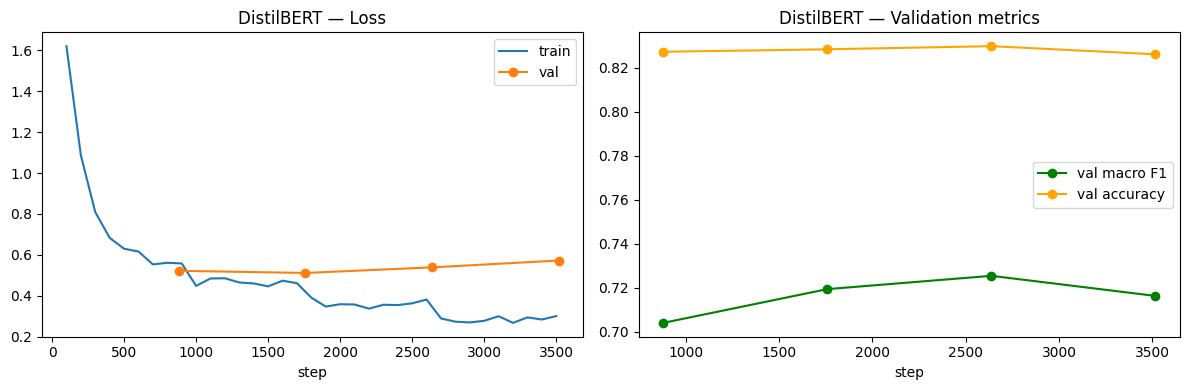

In [40]:
# Training curves pulled from the Trainer's internal log history
log_history = trainer.state.log_history
train_points = [(x["step"], x["loss"]) for x in log_history if "loss" in x]
eval_points  = [x for x in log_history if "eval_loss" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if train_points:
    steps, losses = zip(*train_points)
    axes[0].plot(steps, losses, label="train")
if eval_points:
    axes[0].plot([x["step"] for x in eval_points], [x["eval_loss"] for x in eval_points],
                 label="val", marker="o")
axes[0].set_title("DistilBERT — Loss"); axes[0].set_xlabel("step"); axes[0].legend()

if eval_points:
    axes[1].plot([x["step"] for x in eval_points], [x["eval_macro_f1"] for x in eval_points],
                 label="val macro F1", marker="o", color="green")
    axes[1].plot([x["step"] for x in eval_points], [x["eval_accuracy"] for x in eval_points],
                 label="val accuracy", marker="o", color="orange")
axes[1].set_title("DistilBERT — Validation metrics"); axes[1].set_xlabel("step"); axes[1].legend()

plt.tight_layout(); plt.show()

In [41]:
test_metrics = trainer.evaluate(test_ds)
print("Test set metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

test_preds_output = trainer.predict(test_ds)
bert_test_preds  = np.argmax(test_preds_output.predictions, axis=-1)
bert_test_labels = test_preds_output.label_ids

print("\nClassification report (test set):")
print(classification_report(bert_test_labels, bert_test_preds, target_names=TARGET_CLASSES, digits=3))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Test set metrics:
  eval_loss: 0.5713
  eval_accuracy: 0.8127
  eval_macro_f1: 0.7031
  eval_runtime: 8.8533
  eval_samples_per_second: 399.7370
  eval_steps_per_second: 25.0750
  epoch: 4.0000


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Classification report (test set):
              precision    recall  f1-score   support

       anger      0.659     0.739     0.697       609
     disgust      0.648     0.455     0.534        77
        fear      0.707     0.682     0.695        85
         joy      0.907     0.913     0.910      1937
     sadness      0.693     0.607     0.648       298
    surprise      0.752     0.719     0.735       533

    accuracy                          0.813      3539
   macro avg      0.728     0.686     0.703      3539
weighted avg      0.813     0.813     0.812      3539



In [42]:
bert_save_dir = "distilbert_emotion_final"
trainer.save_model(bert_save_dir)
bert_tokenizer.save_pretrained(bert_save_dir)
print(f"Saved fine-tuned DistilBERT to '{bert_save_dir}/'")

Saved fine-tuned DistilBERT to 'distilbert_emotion_final/'


## 10. Unified validation/test evaluation (all four models)
Evaluate each trained model on **the same held-out split**. Use the **validation** Macro-F1 to choose the deployment model; test metrics are for final reporting only. This section also writes per-class classification reports, probability files and confusion matrices.


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


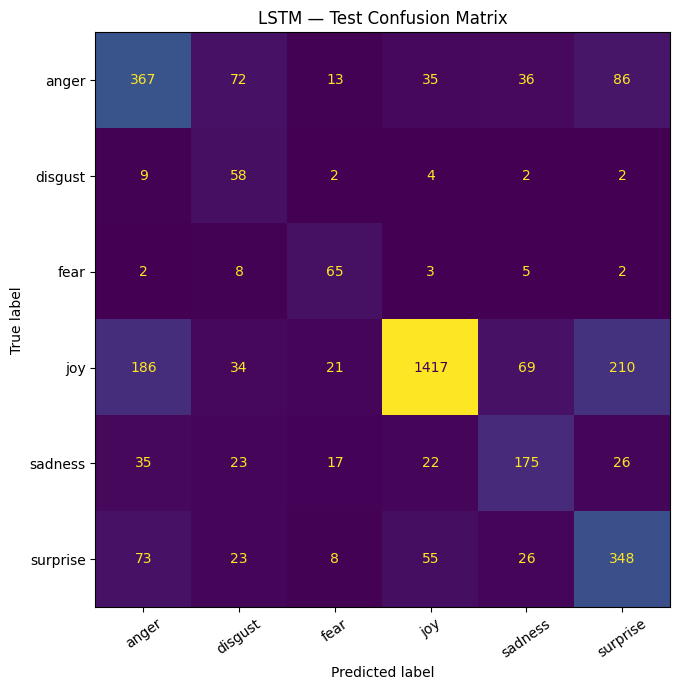

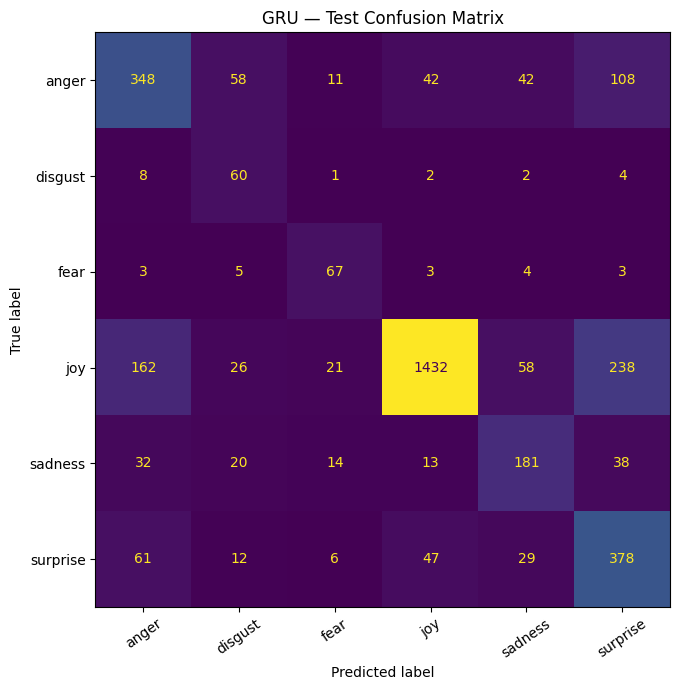

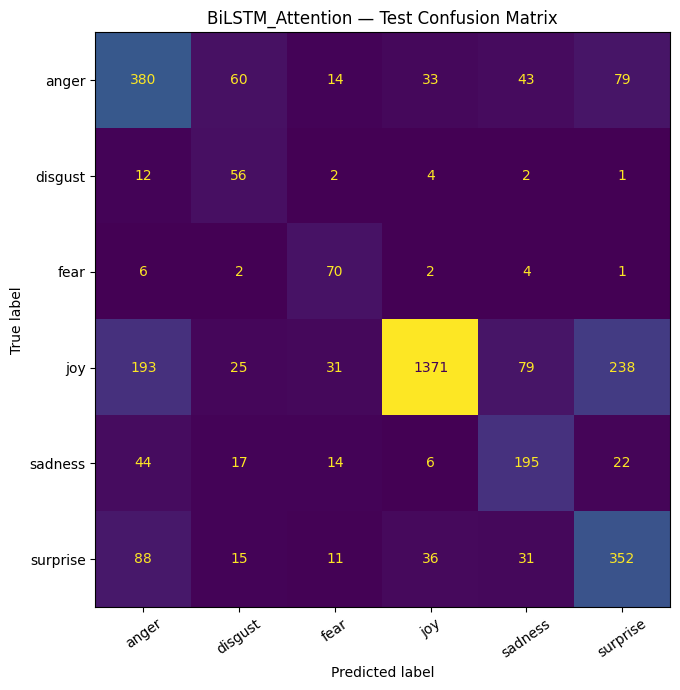

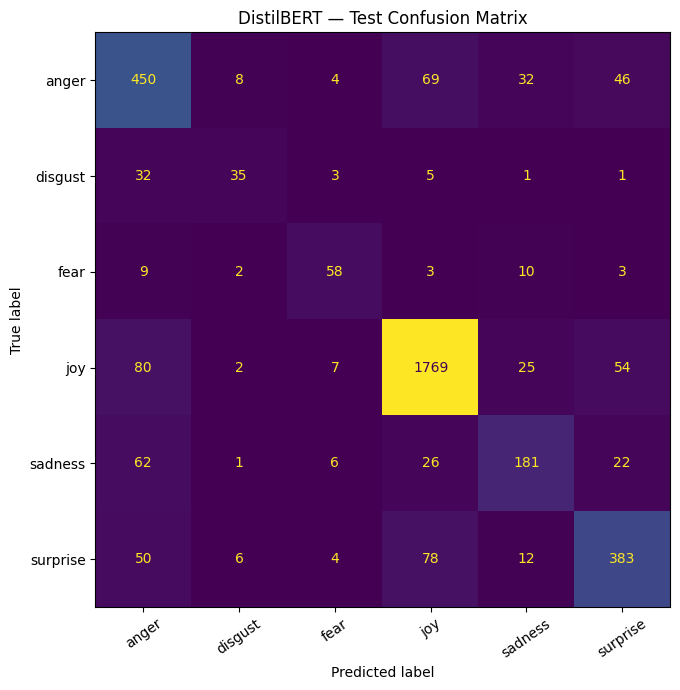

           model      split  accuracy  macro_precision  macro_recall  macro_f1
      DistilBERT       test  0.812659         0.727908      0.685840  0.703080
             GRU       test  0.696807         0.575234      0.699125  0.613671
BiLSTM_Attention       test  0.684939         0.556924      0.699558  0.602205
            LSTM       test  0.686635         0.554335      0.682047  0.591300
      DistilBERT validation  0.829884         0.741304      0.712651  0.725508
             GRU validation  0.697760         0.549086      0.692639  0.592145
BiLSTM_Attention validation  0.682733         0.532840      0.697601  0.581156
            LSTM validation  0.685001         0.530187      0.677532  0.569135
Selected model based ONLY on validation Macro-F1: DistilBERT


In [43]:
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
RESULTS_DIR = Path('emotion_results')
RESULTS_DIR.mkdir(exist_ok=True)
keras_models = {'LSTM': lstm_model, 'GRU': gru_model, 'BiLSTM_Attention': bilstm_attn_model}

def predict_all_probabilities(split):
    X, ds = (X_val, val_ds) if split == 'validation' else (X_test, test_ds)
    output = {}
    for name, model in keras_models.items():
        output[name] = np.asarray(model.predict(X, batch_size=128, verbose=0))
    # Trainer returns raw logits; convert to probabilities for the GUI and CSV.
    logits = np.asarray(trainer.predict(ds).predictions)
    logits = logits - logits.max(axis=1, keepdims=True)
    exps = np.exp(logits)
    output['DistilBERT'] = exps / exps.sum(axis=1, keepdims=True)
    return output

val_probs = predict_all_probabilities('validation')
test_probs = predict_all_probabilities('test')

def metric_row(name, split, y_true, probs):
    pred = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, pred, average='macro', zero_division=0)
    return dict(model=name, split=split,
                accuracy=float(accuracy_score(y_true, pred)),
                macro_precision=float(precision), macro_recall=float(recall),
                macro_f1=float(f1))

metric_rows = []
for name in val_probs:
    metric_rows.append(metric_row(name, 'validation', y_val, val_probs[name]))
    metric_rows.append(metric_row(name, 'test', y_test, test_probs[name]))
    preds = test_probs[name].argmax(axis=1)
    report = classification_report(y_test, preds, labels=list(range(NUM_CLASSES)),
                                   target_names=TARGET_CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(RESULTS_DIR / f'{name}_classification_report.csv')
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds, labels=list(range(NUM_CLASSES))),
                           display_labels=TARGET_CLASSES).plot(ax=ax, xticks_rotation=35,
                                                                values_format='d', colorbar=False)
    ax.set_title(f'{name} — Test Confusion Matrix')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{name}_confusion_matrix.png', dpi=180)
    plt.show()
    pd.DataFrame({'text':test_df['text'].to_numpy(),
                  'true_label': [id2label[int(x)] for x in y_test],
                  'predicted_label': [id2label[int(x)] for x in preds],
                  **{f'prob_{label}':test_probs[name][:,i] for i,label in enumerate(TARGET_CLASSES)}}).to_csv(
                       RESULTS_DIR / f'{name}_test_predictions.csv', index=False)

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(RESULTS_DIR / 'model_comparison_validation_test.csv', index=False)
print(metrics_df.sort_values(['split', 'macro_f1'], ascending=[True,False]).to_string(index=False))
# Test set MUST NOT be used for choosing a model.
val_rank = metrics_df[metrics_df['split']=='validation'].sort_values('macro_f1', ascending=False)
BEST_MODEL_NAME = str(val_rank.iloc[0]['model'])
print('Selected model based ONLY on validation Macro-F1:', BEST_MODEL_NAME)


## 11. Comparisons, data integrity, and training histories
Save plots, check text overlap among partitions, and report class counts. This is an audit, not an automatic alteration of the original experiment splits.


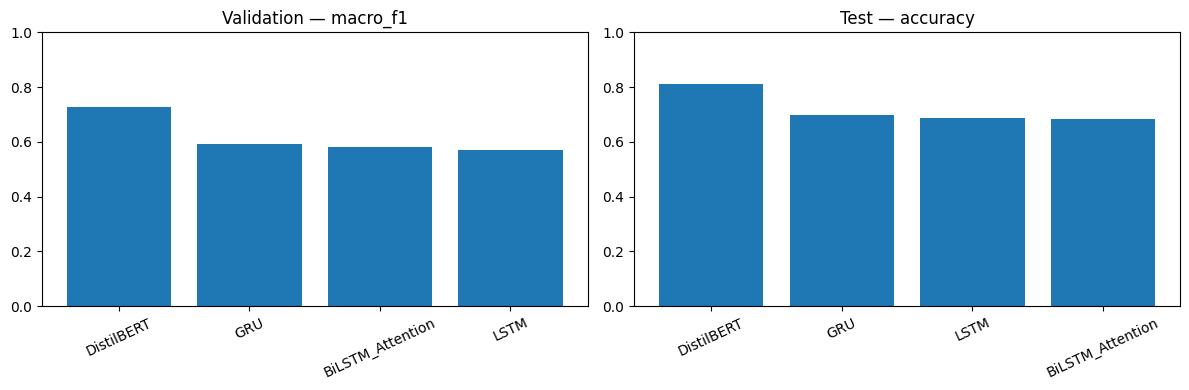

train samples: 28102 classes: {'joy': 15808, 'anger': 4590, 'surprise': 4160, 'sadness': 2455, 'fear': 566, 'disgust': 523} duplicate clean text within split: 314
validation samples: 3527 classes: {'joy': 2017, 'anger': 596, 'surprise': 497, 'sadness': 278, 'fear': 77, 'disgust': 62} duplicate clean text within split: 14
test samples: 3539 classes: {'joy': 1937, 'anger': 609, 'surprise': 533, 'sadness': 298, 'fear': 85, 'disgust': 77} duplicate clean text within split: 10
Clean-text overlap between splits: {'train_validation': 53, 'train_test': 52, 'validation_test': 11}


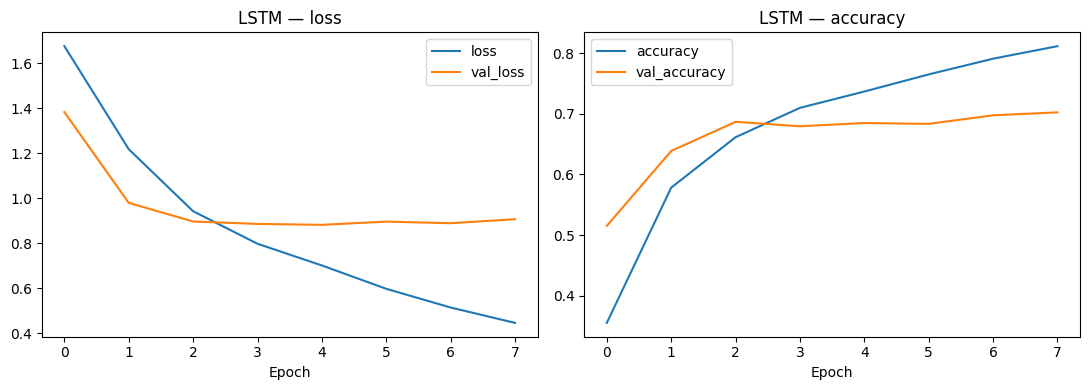

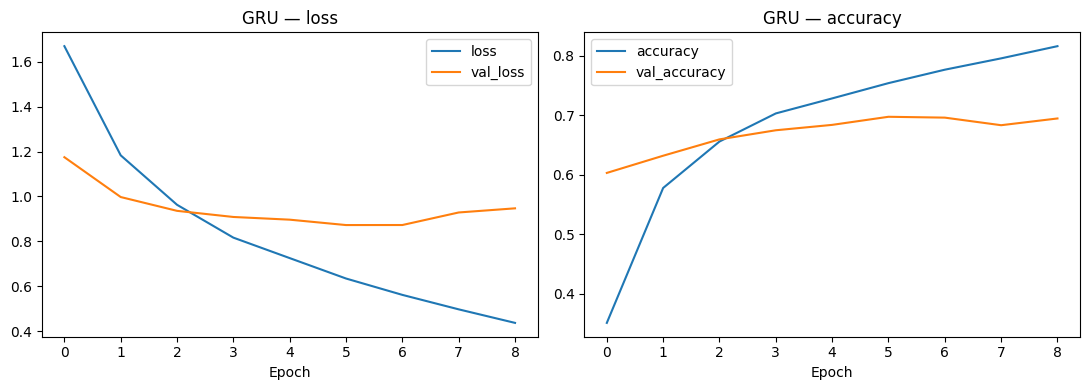

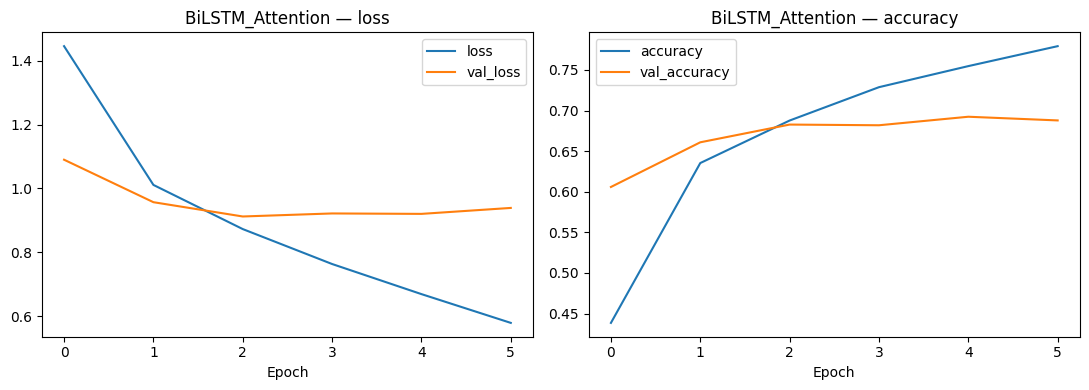

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, split, metric in [(axes[0],'validation','macro_f1'), (axes[1],'test','accuracy')]:
    tmp = metrics_df[metrics_df['split']==split].sort_values(metric, ascending=False)
    ax.bar(tmp['model'], tmp[metric]); ax.set_ylim(0,1); ax.set_title(f'{split.title()} — {metric}')
    ax.tick_params(axis='x', rotation=25)
fig.tight_layout();fig.savefig(RESULTS_DIR/'model_comparison.png', dpi=180);plt.show()

for split, df in [('train',train_df),('validation',val_df),('test',test_df)]:
    print(split, 'samples:',len(df), 'classes:',df['emotion'].value_counts().to_dict(),
          'duplicate clean text within split:',int(df['clean_text'].duplicated().sum()))
train_text = set(train_df['clean_text']); val_text=set(val_df['clean_text']);test_text=set(test_df['clean_text'])
overlap_counts = {'train_validation':len(train_text & val_text),
                  'train_test':len(train_text & test_text),'validation_test':len(val_text & test_text)}
print('Clean-text overlap between splits:', overlap_counts)
if any(overlap_counts.values()):
    print('WARNING: overlap was detected. The source pipeline was preserved; report this limitation and regenerate splits before claiming leakage-free estimates.')

for name, history in [('LSTM',lstm_history),('GRU',gru_history),('BiLSTM_Attention',bilstm_history)]:
    pd.DataFrame(history.history).to_csv(RESULTS_DIR/f'{name}_history.csv',index=False)
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    for metric,ax in [('loss',axes[0]),('accuracy',axes[1])]:
        for key in (metric,'val_'+metric):
            if key in history.history:ax.plot(history.history[key],label=key)
        ax.set_title(f'{name} — {metric}');ax.set_xlabel('Epoch');ax.legend()
    fig.tight_layout();fig.savefig(RESULTS_DIR/f'{name}_history.png',dpi=180);plt.show()

pd.DataFrame(trainer.state.log_history).to_json(RESULTS_DIR/'distilbert_trainer_log.json',orient='records',indent=2)


## 12. Attention heatmaps — actual input tokens, no padding
Attention weights are a **visual inspection aid**, not definitive causal explanations. The visualizer supports arbitrary text and produces saved figures for examples.


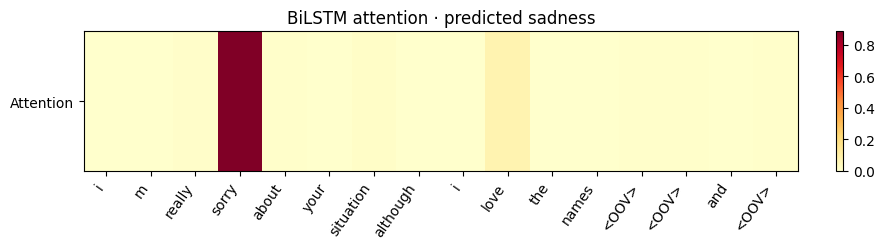

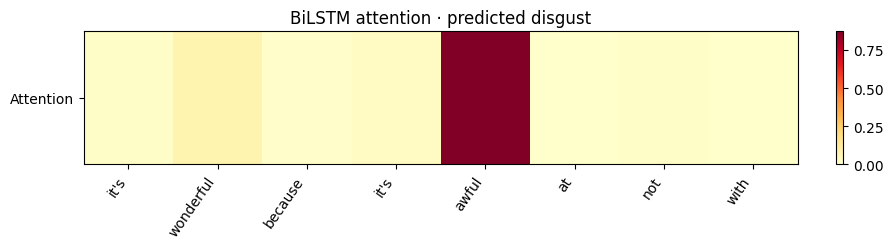

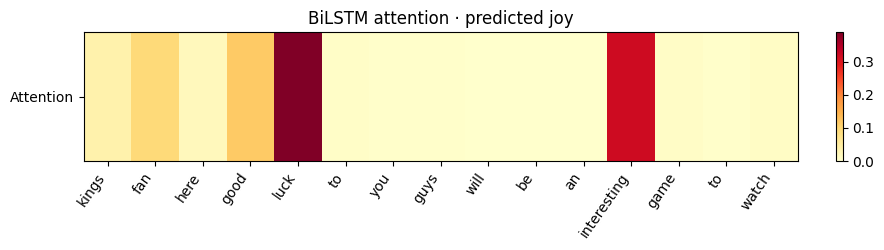

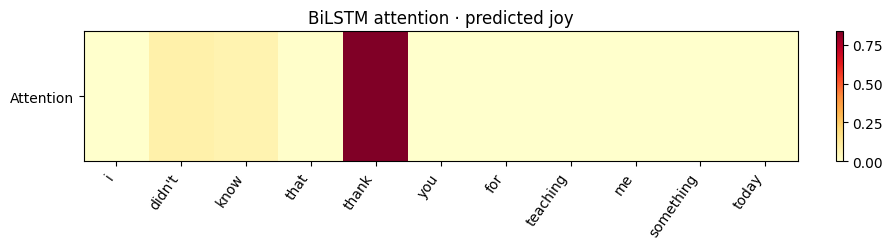

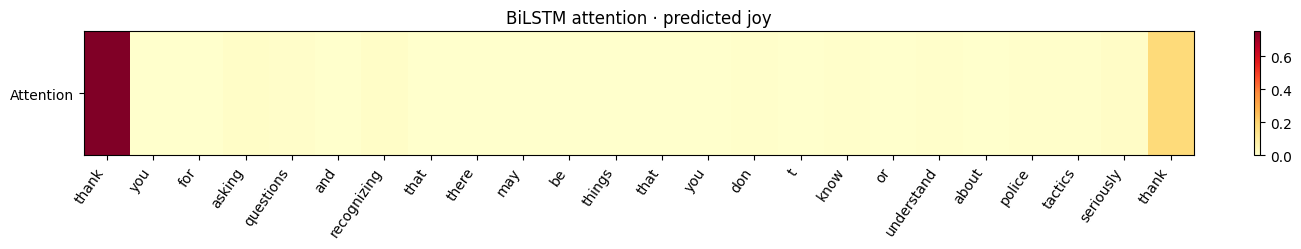

In [45]:
from matplotlib import colors

def attention_for_text(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])[0][:MAX_LEN]
    if not seq:
        raise ValueError('Please enter text containing recognizable words.')
    padded = pad_sequences([seq], maxlen=MAX_LEN, padding='post', truncating='post')
    prob, att = bilstm_attn_weights_model.predict(padded,verbose=0)
    words = [tokenizer.index_word.get(int(t), '<OOV>') for t in seq]
    att = np.asarray(att[0][:len(seq)],dtype=float)
    att = att / max(att.sum(),1e-12)
    return words,att,prob[0]

def draw_attention(text, filename=None):
    words, att, pred = attention_for_text(text)
    # Use a sequence heatmap; each token exactly matches the corresponding attention score.
    fig,ax=plt.subplots(figsize=(max(9,min(22,len(words)*0.55)),2.6))
    im=ax.imshow(att[np.newaxis,:],cmap='YlOrRd',aspect='auto',vmin=0,vmax=max(0.05,float(att.max())))
    ax.set_xticks(np.arange(len(words)));ax.set_xticklabels(words,rotation=55,ha='right')
    ax.set_yticks([0]);ax.set_yticklabels(['Attention'])
    ax.set_title('BiLSTM attention · predicted '+id2label[int(np.argmax(pred))]);fig.colorbar(im,ax=ax,fraction=.025)
    fig.tight_layout()
    if filename:fig.savefig(filename,dpi=170,bbox_inches='tight')
    return fig

for idx in range(min(5,len(test_df))):
    fig=draw_attention(str(test_df.iloc[idx]['text']), RESULTS_DIR/f'attention_example_{idx+1}.png')
    plt.show();plt.close(fig)


## 13. Save deployment metadata and standalone Gradio source
The notebook runs the app in its last cell; we also export `app.py` for a separate deployment. Selecting the best model is based only on **validation Macro-F1**.


In [46]:
import pickle
with open('keras_tokenizer.pkl','wb') as f:pickle.dump(tokenizer,f)
with open('label_maps.json','w') as f:
    json.dump({'label2id':label2id,'id2label':id2label,'MAX_LEN':int(MAX_LEN),
               'best_model':BEST_MODEL_NAME,'model_selection_metric':'validation_macro_f1'},f,indent=2)
with open(RESULTS_DIR/'selected_model.json','w') as f:
    json.dump({'best_model':BEST_MODEL_NAME,'validation_macro_f1':float(val_rank.iloc[0]['macro_f1'])},f,indent=2)
print('Wrote tokenizer, label mappings, selected model and evaluation artifacts.')


Wrote tokenizer, label mappings, selected model and evaluation artifacts.


## 14. Gradio app — prediction, six-class probabilities and BiLSTM attention
The notebook interface uses the models currently loaded in memory. **No retraining is needed to run this cell if the trained model objects exist.** A standalone deployment source is exported below as well.


In [58]:

import gradio as gr

def predict_ui(text, model_choice):
    if not text or not text.strip():
        return (
            "Enter English text.",
            {},
            gr.update(value=None, visible=False)
        )

    # -------------------------
    # Model prediction
    # -------------------------
    if model_choice == "DistilBERT":
        tokens = bert_tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=BERT_MAX_LEN
        )

        bert_model.eval()
        model_device = next(bert_model.parameters()).device

        with torch.no_grad():
            logits = bert_model(
                **{
                    k: v.to(model_device)
                    for k, v in tokens.items()
                }
            ).logits

            probs = torch.softmax(
                logits, dim=-1
            ).cpu().numpy()[0]

    else:
        cleaned = clean_text(text)

        x = pad_sequences(
            tokenizer.texts_to_sequences([cleaned]),
            maxlen=MAX_LEN,
            padding="post",
            truncating="post"
        )

        probs = keras_models[model_choice].predict(
            x,
            verbose=0
        )[0]

    # -------------------------
    # Prediction results
    # -------------------------
    dist = {
        label: float(probs[i])
        for i, label in enumerate(TARGET_CLASSES)
    }

    top = int(np.argmax(probs))

    caption = (
        f"{id2label[top].title()} — "
        f"{float(probs[top]):.1%} confidence"
    )

    # -------------------------
    # Attention visualization
    # -------------------------
    if model_choice == "BiLSTM_Attention":
        try:
            fig = draw_attention(text)
            attention_output = gr.update(
                value=fig,
                visible=True
            )
        except ValueError:
            attention_output = gr.update(
                value=None,
                visible=False
            )
    else:
        attention_output = gr.update(
            value=None,
            visible=False
        )

    return caption, dist, attention_output


# =============================
# GRADIO INTERFACE
# =============================

with gr.Blocks(
    title="Emotion Classification with Attention"
) as demo:

    gr.Markdown(
        "# Emotion Classification with Attention\n"
        "Six emotions · Four trained architectures"
    )

    model_selector = gr.Dropdown(
        choices=list(keras_models) + ["DistilBERT"],
        value="DistilBERT",
        label="Prediction model"
    )

    text_input = gr.Textbox(
        label="English text",
        lines=3,
        placeholder="I am really excited about the news!"
    )

    run_btn = gr.Button(
        "Predict emotion",
        variant="primary"
    )

    prediction = gr.Textbox(
        label="Dominant emotion"
    )

    scores = gr.Label(
        label="Class probabilities",
        num_top_classes=6
    )

    attention_plot = gr.Plot(
        label="BiLSTM Attention Heatmap",
        visible=False
    )

    gr.Markdown(
        "Attention heatmaps are available only for "
        "the BiLSTM + Attention model. "
        "Attention weights do not necessarily indicate "
        "causal importance."
    )

    # Hide previous heatmap when model changes
    def toggle_attention(model_name):
        return gr.update(
            value=None,
            visible=False
        )

    model_selector.change(
        fn=toggle_attention,
        inputs=[model_selector],
        outputs=[attention_plot]
    )

    # Predict button
    run_btn.click(
        fn=predict_ui,
        inputs=[text_input, model_selector],
        outputs=[prediction, scores, attention_plot]
    )

    # Press Enter to predict
    text_input.submit(
        fn=predict_ui,
        inputs=[text_input, model_selector],
        outputs=[prediction, scores, attention_plot]
    )

print("Gradio interface created. Launch in the final cell.")


Gradio interface created. Launch in the final cell.


## 15. Export a standalone `app.py`
This app can be run separately from the notebook with the exported model files. The BiLSTM attention custom layer is declared for deserialization.


In [59]:
from pathlib import Path
Path("app.py").write_text('import os, json, pickle\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras.preprocessing.sequence import pad_sequences\nfrom transformers import AutoTokenizer, AutoModelForSequenceClassification\nimport torch\nimport gradio as gr\nimport matplotlib.pyplot as plt\nimport re\n\n@keras.utils.register_keras_serializable(package="EmotionProject")\nclass AdditiveAttention(keras.layers.Layer):\n    def __init__(self, units, **kwargs):\n        super().__init__(**kwargs)\n        self.units=units\n    def build(self, input_shape):\n        self.W=self.add_weight(name="att_W",shape=(input_shape[-1],self.units),initializer="glorot_uniform",trainable=True)\n        self.b=self.add_weight(name="att_b",shape=(self.units,),initializer="zeros",trainable=True)\n        self.v=self.add_weight(name="att_v",shape=(self.units,1),initializer="glorot_uniform",trainable=True)\n        super().build(input_shape)\n    def call(self, hidden_states, mask=None):\n        score=tf.tanh(tf.tensordot(hidden_states,self.W,axes=1)+self.b)\n        score=tf.squeeze(tf.tensordot(score,self.v,axes=1),axis=-1)\n        if mask is not None:score+=(1-tf.cast(mask,tf.float32))*-1e9\n        weights=tf.nn.softmax(score,axis=1)\n        return tf.reduce_sum(hidden_states*tf.expand_dims(weights,-1),axis=1),weights\n    def compute_mask(self,inputs,mask=None):return None\n    def get_config(self):return {**super().get_config(),"units":self.units}\n\nwith open(\'label_maps.json\') as f: metadata=json.load(f)\nwith open(\'keras_tokenizer.pkl\',\'rb\') as f:tok=pickle.load(f)\nlabels=list(metadata[\'label2id\'].keys()); maxlen=int(metadata[\'MAX_LEN\'])\npaths={\'LSTM\':\'lstm_model.keras\',\'GRU\':\'gru_model.keras\',\n       \'BiLSTM_Attention\':\'bilstm_attention_model.keras\'}\nmodels={name:keras.models.load_model(p,compile=False,custom_objects={\'AdditiveAttention\':AdditiveAttention, \'EmotionProject>AdditiveAttention\':AdditiveAttention}) for name,p in paths.items()}\nweights_model=keras.models.load_model(\'bilstm_attention_weights_model.keras\',compile=False,custom_objects={\'AdditiveAttention\':AdditiveAttention, \'EmotionProject>AdditiveAttention\':AdditiveAttention})\nbert_dir=\'distilbert_emotion_final\'\nbert_tokenizer=AutoTokenizer.from_pretrained(bert_dir)\nbert=AutoModelForSequenceClassification.from_pretrained(bert_dir)\nbert.eval()\n\ndef clean_text(text):\n    text=text.lower();text=re.sub(r\'http\\S+|www\\S+\',\' \',text)\n    text=re.sub(r\'@\\w+\',\' \',text);text=re.sub(r\'\\[NAME\\]|\\[RELIGION\\]|\\[.*?\\]\',\' \',text)\n    return re.sub(r\'\\s+\',\' \',re.sub(r"[^a-zA-Z!?\']",\' \',text)).strip()\n\ndef predict(text, name):\n    if not text.strip():return \'Enter English text.\',{},None\n    if name==\'DistilBERT\':\n        with torch.no_grad():\n            inputs=bert_tokenizer(text,return_tensors=\'pt\',truncation=True,max_length=64)\n            prob=torch.softmax(bert(**inputs).logits,dim=-1).numpy()[0]\n    else:\n        x=pad_sequences(tok.texts_to_sequences([clean_text(text)]),maxlen=maxlen,padding=\'post\',truncating=\'post\')\n        prob=models[name].predict(x,verbose=0)[0]\n    result={label:float(prob[i]) for i,label in enumerate(labels)}\n    top=int(np.argmax(prob))\n    fig=None\n    seq=tok.texts_to_sequences([clean_text(text)])[0][:maxlen]\n    if seq:\n        x=pad_sequences([seq],maxlen=maxlen,padding=\'post\',truncating=\'post\')\n        _, att=weights_model.predict(x,verbose=0)\n        words=[tok.index_word.get(int(w),\'<OOV>\') for w in seq]\n        scores=att[0,:len(seq)]\n        fig,ax=plt.subplots(figsize=(max(9,min(22,len(words)*.5)),2.5))\n        im=ax.imshow(scores[np.newaxis,:],aspect=\'auto\',cmap=\'YlOrRd\')\n        ax.set_yticks([0]);ax.set_yticklabels([\'Attention\']);ax.set_xticks(range(len(words)))\n        ax.set_xticklabels(words,rotation=55,ha=\'right\');fig.colorbar(im,ax=ax);fig.tight_layout()\n    return f\'{labels[top].title()} — {prob[top]:.1%}\',result,fig\n\nwith gr.Blocks(title=\'Emotion Classification with Attention\') as app:\n    gr.Markdown(\'# Emotion Classification with Attention\')\n    name=gr.Dropdown(choices=list(paths)+[\'DistilBERT\'],value=metadata[\'best_model\'],label=\'Model\')\n    inp=gr.Textbox(label=\'Text\',lines=3)\n    btn=gr.Button(\'Predict\',variant=\'primary\')\n    out=gr.Textbox(label=\'Dominant emotion\');scores=gr.Label(num_top_classes=6,label=\'Confidence\')\n    att=gr.Plot(label=\'BiLSTM attention (separate explanation model)\')\n    btn.click(predict,[inp,name],[out,scores,att])\n    gr.Markdown(\'Attention weights are not causal explanations. The heatmap always uses BiLSTM.\')\nif __name__==\'__main__\':app.launch()\n', encoding="utf-8")
print("Saved standalone app.py")


Saved standalone app.py


## 16. Package the results and models
Includes model files, the tokenizer and label mappings, all comparison/attention figures, and the standalone `app.py`. The archive is created **after** evaluation.


In [60]:
import shutil

# Collect everything we saved during the notebook
artifacts = [
    "lstm_model.keras",
    "gru_model.keras",
    "bilstm_attention_model.keras",
    "bilstm_attention_weights_model.keras",
    "distilbert_emotion_final",   # folder saved by trainer.save_model()
    "keras_tokenizer.pkl", "label_maps.json", "emotion_results", "app.py",
]

import os
existing = [a for a in artifacts if os.path.exists(a)]
missing  = [a for a in artifacts if not os.path.exists(a)]
if missing:
    print("Not found (skipped):", missing)

zip_dir = "emotion_models_export"
os.makedirs(zip_dir, exist_ok=True)
for a in existing:
    dest = os.path.join(zip_dir, os.path.basename(a))
    if os.path.isdir(a):
        shutil.copytree(a, dest, dirs_exist_ok=True)
    else:
        shutil.copy2(a, dest)

# Also grab the Keras tokenizer + label mappings so the models are usable standalone
import pickle
with open(os.path.join(zip_dir, "keras_tokenizer.pkl"), "wb") as f:
    pickle.dump(tokenizer, f)
with open(os.path.join(zip_dir, "label_maps.json"), "w") as f:
    json.dump({"label2id": label2id, "id2label": id2label, "MAX_LEN": MAX_LEN}, f)

zip_path = shutil.make_archive(zip_dir, "zip", zip_dir)
print(f"Created archive: {zip_path}  ({os.path.getsize(zip_path) / 1e6:.1f} MB)")

# Trigger browser download (Colab only)
try:
    from google.colab import files
    files.download(zip_path)
    print("Download triggered — check your browser downloads.")
except ImportError:
    print(f"Not running on Colab — find your zip at: {os.path.abspath(zip_path)}")

Created archive: /kaggle/working/emotion_models_export.zip  (329.1 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered — check your browser downloads.


## 17. Launch interactive Gradio in this notebook
This last cell starts the app after all models have trained, reports have been created, and artifacts exported. If your Kaggle session blocks public links, run `python app.py` after downloading the archive on another supported host.


In [61]:
# Non-blocking launch lets the notebook finish Run All.
try:
    demo.launch(share=True, prevent_thread_lock=True, show_error=True)
except Exception as exc:
    print('Gradio launch unavailable in this runtime:',repr(exc))
    print('Standalone app.py is also available in the ZIP archive.')


* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://f70b769e4d77ca5ffe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/dist-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)
/usr/local/lib/python3.13/di